In [6]:
import numpy as np
import pandas as pd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
from sklearn.feature_selection import VarianceThreshold

train_features = pd.read_pickle("../data/processed/train_features.pkl")
test_features = pd.read_pickle("../data/processed/test_features.pkl")
y_train = pd.read_pickle("../data/processed/y_train.pkl")
y_test = pd.read_pickle("../data/processed/y_test.pkl")

print("Data successfully loaded for Notebook4!")


Data successfully loaded for Notebook4!


In [7]:
df_train_comb = pd.concat([train_features, y_train], axis=1).dropna()
df_train_comb_encoded = pd.get_dummies(df_train_comb, drop_first=True)
X_train_comb_features = df_train_comb_encoded.drop(columns=['time', 'event'])

selector_comb = VarianceThreshold(threshold=0.01)
X_train_comb_filtered = pd.DataFrame(
    selector_comb.fit_transform(X_train_comb_features),
    columns=X_train_comb_features.columns[selector_comb.get_support()],
    index=df_train_comb_encoded.index
)

df_train_comb_clean = pd.concat([X_train_comb_filtered, y_train], axis=1).dropna()

X_train_comb_enc_xgb = df_train_comb_clean.drop(columns=['time', 'event'])
y_train_comb_clean = y_train.loc[X_train_comb_enc_xgb.index]
y_train_comb_xgb = y_train_comb_clean['time'] * np.where(y_train_comb_clean['event'] == 1, 1, -1)

params = {
    'objective' : 'survival:cox',
    'eval_metric' : 'cox-nloglik',
    'seed' : 42,
    'max_depth' : 4,
    'learning_rate' : 0.05,
    'subsample' : 0.8
}

dtrain_comb = xgb.DMatrix(X_train_comb_enc_xgb, label=y_train_comb_xgb)
bst_comb = xgb.train(params, dtrain_comb, num_boost_round=150)
print("Combined XGBoost Model trained and optimized successfully!")


Combined XGBoost Model trained and optimized successfully!


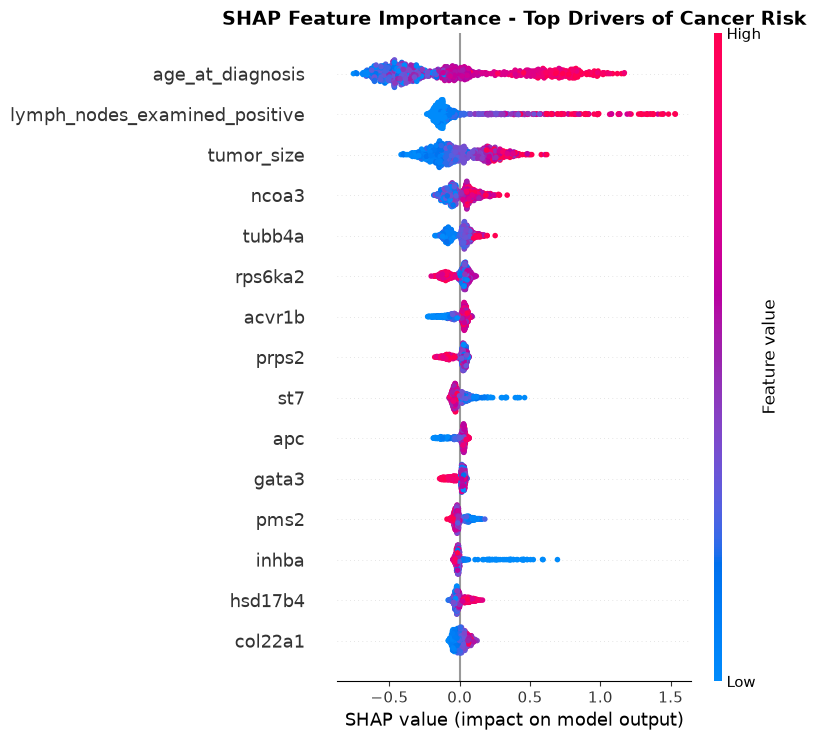

SHAP Summary Plot generated and saved in results folder!


In [8]:
explainer = shap.TreeExplainer(bst_comb)
shap_values = explainer(X_train_comb_enc_xgb)

plt.figure(figsize=(10,8))
shap.summary_plot(shap_values, X_train_comb_enc_xgb, max_display=15, show=False)
plt.title("SHAP Feature Importance - Top Drivers of Cancer Risk", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("../results/shap_summary_plot.png", dpi=300)
plt.show()

print("SHAP Summary Plot generated and saved in results folder!")

<Figure size 800x600 with 0 Axes>

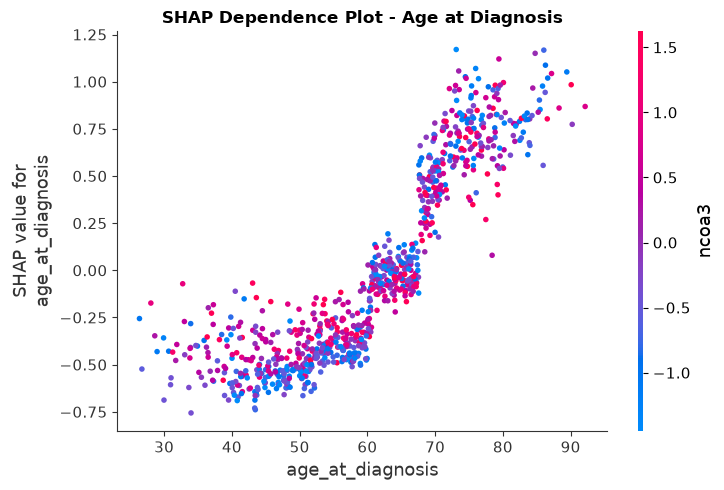

In [10]:
plt.figure(figsize=(8, 6))
shap.dependence_plot("age_at_diagnosis", shap_values.values, X_train_comb_enc_xgb, show=False)
plt.title("SHAP Dependence Plot - Age at Diagnosis", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig("../results/shap_dependence_plot.png", dpi=300)
plt.show()